In [1]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import xgboost as xgb
import numpy as np
import utils

from utils import (
    calculate_technical_indicators,
    compare_results,
    evaluate_predictions,
    evaluate_torch_model,
    fit_arima,
    fit_standard_scaler,
    forecast_arima,
    grid_search_arima,
    load_fred_data,
    normalize_to_tensor,
    plot_dataset,
    plot_predictions_vs_targets,
    predict_and_store_log_return_model,
    predict_moving_average,
    predict_naive,
    prepare_data,
    split_data,
    store_model_prediction,
    train_torch_model,
    train_xgboost,
)

DATA_DIR = Path("FRED")
RESULTS_PATH = Path("model_results.json")
TARGET_COLUMN = "INR"
FEATURE_COLUMNS = ["JPY", "EUR", "FFER", "US10YY"]
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
EPOCHS = 100
BATCH_SIZE = 32
model_results = {}

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


In [2]:
full_df = prepare_data(load_fred_data(DATA_DIR))
full_df["TARGET_NEXT"] = full_df[TARGET_COLUMN].shift(-1)
full_df = full_df.dropna(subset=["TARGET_NEXT"])

train_df, val_df, test_df = split_data(
    full_df,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)

full_df.head()

,INR,JPY,EUR,FFER,US10YY,TARGET_NEXT
observation_date,,,,,,
1999-01-04,42.60,112.15,1.1812,5.04,4.69,42.56
1999-01-05,42.56,111.15,1.1760,4.54,4.74,42.55
1999-01-06,42.55,112.78,1.1636,4.23,4.73,42.55
1999-01-07,42.55,111.69,1.1672,4.49,4.77,42.55
1999-01-08,42.55,111.52,1.1554,4.74,4.86,42.55


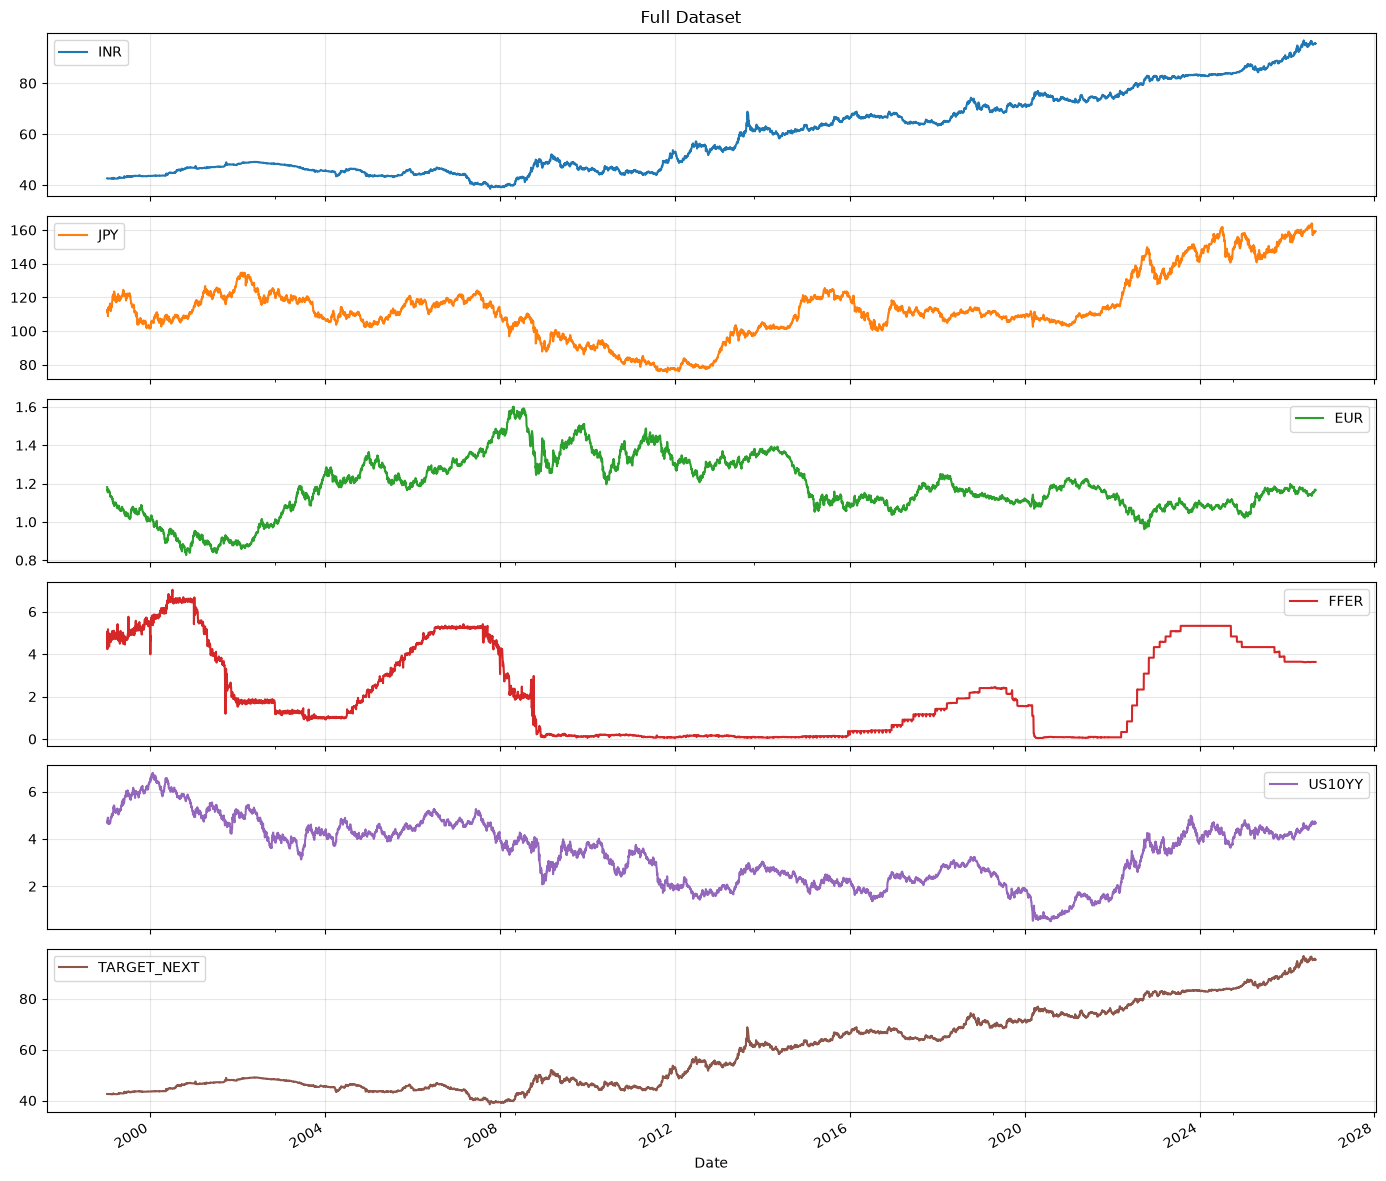

Train: (5524, 6), validation: (690, 6), test: (691, 6)


In [3]:
plot_dataset(full_df)
print(f"Train: {train_df.shape}, validation: {val_df.shape}, test: {test_df.shape}")

## Baseline and ARIMA

Naive: {'mae': 0.1493805826271353, 'mse': 0.07776622105608079, 'rmse': 0.27886595535504294, 'directional_accuracy': 53.08709034944776, 'correct_days': 2932, 'total_days': 5523}
Moving average: {'mae': 0.11185312760039676, 'mse': 0.07249965294511787, 'rmse': 0.2692575958912169, 'directional_accuracy': 78.20025348542458, 'correct_days': 4319, 'total_days': 5523}


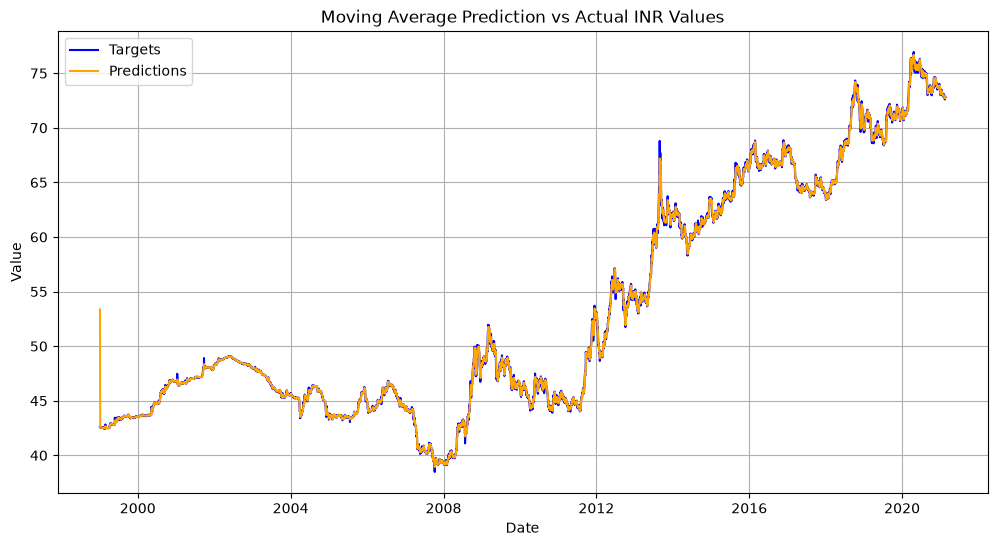

In [4]:
naive_predictions = predict_naive(train_df, TARGET_COLUMN)
moving_average_predictions = predict_moving_average(train_df, target_column=TARGET_COLUMN)

naive_metrics = evaluate_predictions(naive_predictions, train_df[TARGET_COLUMN])
moving_average_metrics = evaluate_predictions(
    moving_average_predictions,
    train_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "Naive",
    naive_predictions,
    naive_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Moving Average",
    moving_average_predictions,
    moving_average_metrics,
    "train",
)
print("Naive:", naive_metrics)
print("Moving average:", moving_average_metrics)
plot_predictions_vs_targets(
    moving_average_predictions,
    train_df[TARGET_COLUMN],
    x_values=train_df.index,
    title="Moving Average Prediction vs Actual INR Values",
)

c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to co

        order       mae          aic
13  (2, 0, 1)  1.189463  1083.986231
14  (2, 0, 2)  3.967801  1110.132852
7   (1, 0, 1)  4.096017   981.965548
12  (2, 0, 0)  4.323510   985.545433
6   (1, 0, 0)  4.422338   987.722667
Best ARIMA order: (2, 0, 1)
{'mae': 1.1894633706751412, 'mse': 2.3348702134278048, 'rmse': 1.5280282109397734, 'directional_accuracy': 53.84615384615385, 'correct_days': 371, 'total_days': 689}


c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


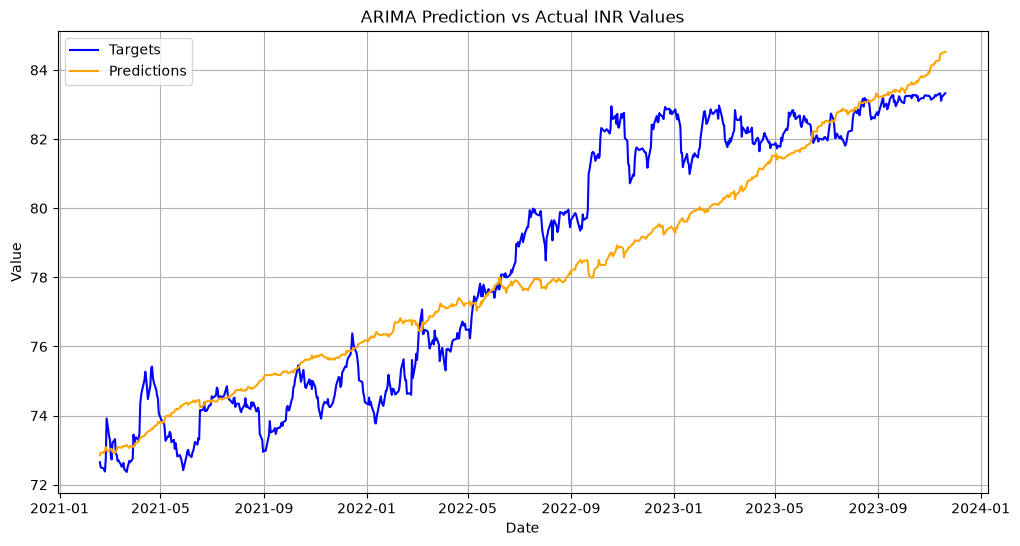

In [5]:
search_results, best_order = grid_search_arima(
    train_df,
    val_df,
    FEATURE_COLUMNS,
    p_values=range(0, 3),
    d_values=range(0, 2),
    q_values=range(0, 3),
    target_column=TARGET_COLUMN,
)
print(search_results.head())
print(f"Best ARIMA order: {best_order}")
arima_model = fit_arima(train_df, FEATURE_COLUMNS, best_order, TARGET_COLUMN)
arima_train_predictions = arima_model.predict(
    start=0,
    end=len(train_df) - 1,
    exog=train_df[FEATURE_COLUMNS],
)
arima_predictions, arima_metrics = forecast_arima(
    arima_model,
    val_df,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)
arima_train_metrics = evaluate_predictions(
    arima_train_predictions,
    train_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "ARIMA",
    arima_train_predictions,
    arima_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "ARIMA",
    arima_predictions,
    arima_metrics,
    "validation",
)
print(arima_metrics)
plot_predictions_vs_targets(
    arima_predictions,
    val_df[TARGET_COLUMN],
    x_values=val_df.index,
    title="ARIMA Prediction vs Actual INR Values",
)

## XGBoost

[0]	validation_0-rmse:10.25372	validation_1-rmse:25.29351	validation_2-rmse:34.48110
[100]	validation_0-rmse:1.07601	validation_1-rmse:26.19632	validation_2-rmse:43.18526
[200]	validation_0-rmse:0.70740	validation_1-rmse:26.17821	validation_2-rmse:43.63768
[300]	validation_0-rmse:0.61798	validation_1-rmse:26.15898	validation_2-rmse:43.68659
[400]	validation_0-rmse:0.55267	validation_1-rmse:26.14245	validation_2-rmse:43.69870
[499]	validation_0-rmse:0.50368	validation_1-rmse:26.11360	validation_2-rmse:43.67179
{'mae': 43.520977324997816, 'mse': 1907.2248406795463, 'rmse': 43.67178540750935, 'directional_accuracy': 44.927536231884055, 'correct_days': 310, 'total_days': 690}


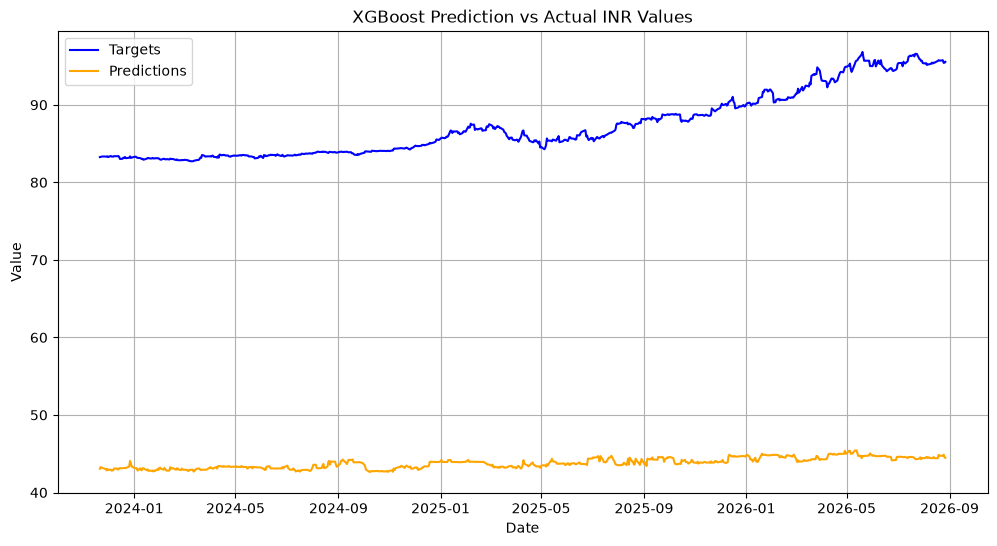

In [6]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)
xgb_model = train_xgboost(
    xgb_model,
    train_df,
    val_df,
    test_df,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)
xgb_train_predictions = xgb_model.predict(train_df[FEATURE_COLUMNS])
xgb_test_predictions = xgb_model.predict(test_df[FEATURE_COLUMNS])
xgb_train_metrics = evaluate_predictions(
    xgb_train_predictions,
    train_df[TARGET_COLUMN],
)
xgb_metrics = evaluate_predictions(
    xgb_test_predictions,
    test_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "XGBoost",
    xgb_train_predictions,
    xgb_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "XGBoost",
    xgb_test_predictions,
    xgb_metrics,
    "test",
)
print(xgb_metrics)
plot_predictions_vs_targets(
    xgb_test_predictions,
    test_df[TARGET_COLUMN],
    x_values=test_df.index,
    title="XGBoost Prediction vs Actual INR Values",
)

In [7]:
baseline_feature_columns = FEATURE_COLUMNS + [TARGET_COLUMN]
X_train = torch.tensor(
    train_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_train = torch.tensor(
    train_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)
X_val = torch.tensor(
    val_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_val = torch.tensor(
    val_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)
X_test = torch.tensor(
    test_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_test = torch.tensor(
    test_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

linear_model = nn.Linear(NUM_INPUT_FEATURES, OUTPUT_FEATURES)
linear_optimizer = optim.Adam(linear_model.parameters(), lr=0.01)
linear_losses = train_torch_model(
    linear_model,
    linear_optimizer,
    nn.MSELoss(),
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

deep_model = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, OUTPUT_FEATURES),
)
deep_optimizer = optim.Adam(deep_model.parameters(), lr=0.01)
deep_losses = train_torch_model(
    deep_model,
    deep_optimizer,
    nn.MSELoss(),
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

with torch.no_grad():
    linear_train_predictions = linear_model(X_train)
    linear_test_predictions = linear_model(X_test)
    deep_train_predictions = deep_model(X_train)
    deep_test_predictions = deep_model(X_test)

linear_train_metrics = evaluate_predictions(linear_train_predictions, y_train)
linear_metrics = evaluate_predictions(linear_test_predictions, y_test)
deep_train_metrics = evaluate_predictions(deep_train_predictions, y_train)
deep_metrics = evaluate_predictions(deep_test_predictions, y_test)

store_model_prediction(
    model_results,
    "Linear Regression",
    linear_train_predictions,
    linear_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Linear Regression",
    linear_test_predictions,
    linear_metrics,
    "test",
)
store_model_prediction(
    model_results,
    "Deep Learning",
    deep_train_predictions,
    deep_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Deep Learning",
    deep_test_predictions,
    deep_metrics,
    "test",
)

print(f"Linear Regression test metrics: {linear_metrics}")
print(f"Deep Learning test metrics: {deep_metrics}")

Epoch 10/100, Train Loss: 1630.1112, Val Loss: 3078.8674
Epoch 20/100, Train Loss: 635.3004, Val Loss: 1305.1498
Epoch 30/100, Train Loss: 176.2733, Val Loss: 419.9792
Epoch 40/100, Train Loss: 48.9365, Val Loss: 104.0873
Epoch 50/100, Train Loss: 42.0322, Val Loss: 30.5471
Epoch 60/100, Train Loss: 45.2800, Val Loss: 21.5913
Epoch 70/100, Train Loss: 40.7401, Val Loss: 28.9784
Epoch 80/100, Train Loss: 36.5590, Val Loss: 42.4596
Epoch 90/100, Train Loss: 34.8034, Val Loss: 52.3388
Epoch 100/100, Train Loss: 33.6047, Val Loss: 54.1380
Epoch 10/100, Train Loss: 422.7990, Val Loss: 315.3997
Epoch 20/100, Train Loss: 217.6430, Val Loss: 697.0126
Epoch 30/100, Train Loss: 91.8750, Val Loss: 10.0568
Epoch 40/100, Train Loss: 58.8784, Val Loss: 179.5329
Epoch 50/100, Train Loss: 35.8162, Val Loss: 8.0667
Epoch 60/100, Train Loss: 16.1907, Val Loss: 29.5465
Epoch 70/100, Train Loss: 5.9937, Val Loss: 16.3796
Epoch 80/100, Train Loss: 2.1198, Val Loss: 1.4585
Epoch 90/100, Train Loss: 0.7752, 

## Technical indicators

In [8]:
technical_data = calculate_technical_indicators(full_df).dropna()
technical_data["TARGET_NEXT"] = technical_data["Log_Returns"].shift(-1)
technical_data = technical_data.dropna(subset=["TARGET_NEXT"])
technical_data.head()

,INR,JPY,EUR,FFER,US10YY,TARGET_NEXT,MA_5,MA_10,EMA_5,EMA_10,RSI,BB_Middle,BB_Upper,BB_Lower,Volatility,ATR_14_proxy,ATR_%_proxy,Log_Returns
observation_date,,,,,,,,,,,,,,,,,,
1999-02-01,42.55,115.09,1.1303,4.86,4.75,-0.000235,42.536,42.542,42.542329,42.542238,50.000000,42.5455,42.584148,42.506852,0.019324,0.017143,0.040289,0.000235
1999-02-02,42.54,112.12,1.1328,4.56,4.79,-0.000941,42.540,42.541,42.541553,42.541831,48.000000,42.5425,42.571428,42.513572,0.014464,0.017857,0.041977,-0.000235
1999-02-03,42.50,112.46,1.1339,4.65,4.83,0.000470,42.536,42.536,42.527702,42.534226,44.444444,42.5395,42.572888,42.506112,0.016694,0.019286,0.045378,-0.000941
1999-02-04,42.52,112.03,1.1306,4.88,4.89,-0.000470,42.530,42.534,42.525134,42.531639,44.444444,42.5380,42.572090,42.503910,0.017045,0.019286,0.045357,0.000470
1999-02-05,42.50,113.14,1.1283,4.76,4.94,0.000000,42.522,42.529,42.516756,42.525887,50.000000,42.5355,42.573043,42.497957,0.018771,0.017143,0.040336,-0.000470


In [9]:
NUM_INPUT_FEATURES = len(FEATURE_COLUMNS) + 1 + 12  # Original features + target + technical indicators
OUTPUT_FEATURES = 1  # Predicting the next price

train_df_ta, val_df_ta, test_df_ta = split_data(
    technical_data,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)

In [10]:
ta_columns = [
    "MA_5", "MA_10", "EMA_5", "EMA_10",
    "RSI", "BB_Middle", "BB_Upper", "BB_Lower",
    "Volatility", "ATR_14_proxy", "ATR_%_proxy", "Log_Returns",
]

all_features = FEATURE_COLUMNS + [TARGET_COLUMN] + ta_columns

In [11]:
TARGET_COLUMN = "INR"
technical_target_column = "TARGET_NEXT"

In [12]:
feature_scaler = fit_standard_scaler(train_df_ta, all_features)

train_targets = train_df_ta["TARGET_NEXT"]
val_targets = val_df_ta["TARGET_NEXT"]
test_targets = test_df_ta["TARGET_NEXT"]
target_scaler = fit_standard_scaler(train_targets)

X_train = normalize_to_tensor(train_df_ta, feature_scaler, all_features)
X_val = normalize_to_tensor(val_df_ta, feature_scaler, all_features)
X_test = normalize_to_tensor(test_df_ta, feature_scaler, all_features)
y_train = normalize_to_tensor(train_targets, target_scaler)
y_val = normalize_to_tensor(val_targets, target_scaler)
y_test = normalize_to_tensor(test_targets, target_scaler)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

In [13]:
model_linear_ta = nn.Linear(NUM_INPUT_FEATURES, OUTPUT_FEATURES)
model_linear_ta_optimizer = optim.Adam(
    model_linear_ta.parameters(),
    lr=0.001,
)
model_linear_ta_loss_function = nn.MSELoss()

In [14]:
EPOCHS = 100

model_linear_ta_losses = train_torch_model(
    model_linear_ta,
    model_linear_ta_optimizer,
    model_linear_ta_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 1.3190, Val Loss: 1.6511
Epoch 20/100, Train Loss: 1.2269, Val Loss: 1.2147
Epoch 30/100, Train Loss: 1.1586, Val Loss: 0.9016
Epoch 40/100, Train Loss: 1.1109, Val Loss: 0.6975
Epoch 50/100, Train Loss: 1.0791, Val Loss: 0.5783
Epoch 60/100, Train Loss: 1.0583, Val Loss: 0.5179
Epoch 70/100, Train Loss: 1.0448, Val Loss: 0.4928
Epoch 80/100, Train Loss: 1.0359, Val Loss: 0.4860
Epoch 90/100, Train Loss: 1.0296, Val Loss: 0.4866
Epoch 100/100, Train Loss: 1.0249, Val Loss: 0.4889


Test MAE: 0.1856, Test MSE: 0.0676


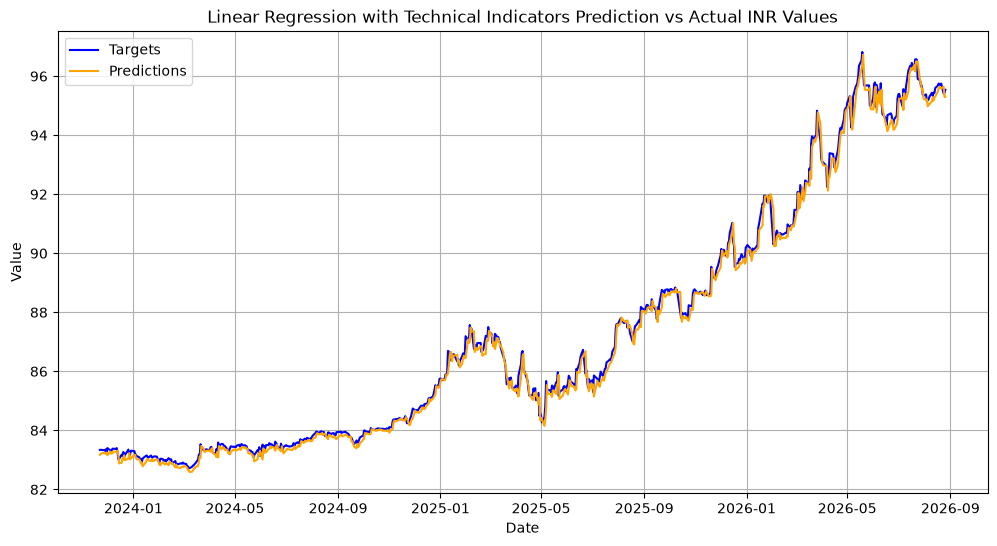

In [15]:
linear_ta_prediction_results = predict_and_store_log_return_model(
    model=model_linear_ta,
    model_name="Linear Regression with Technical Indicators",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_linear_ta = linear_ta_prediction_results["train_predictions"]
predicted_prices_linear_ta = linear_ta_prediction_results["test_predictions"]
actual_train_prices_ta = linear_ta_prediction_results["train_actual_prices"]
actual_prices_ta = linear_ta_prediction_results["test_actual_prices"]
linear_ta_train_metrics = linear_ta_prediction_results["train_metrics"]
linear_ta_metrics = linear_ta_prediction_results["test_metrics"]

print(
    f"Test MAE: {linear_ta_metrics['mae']:.4f}, "
    f"Test MSE: {linear_ta_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_linear_ta,
    actual_prices_ta,
    x_values=test_df_ta.index,
    title="Linear Regression with Technical Indicators Prediction vs Actual INR Values",
)

In [16]:
model_dl_ta = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
model_dl_ta_optimizer = optim.Adam(
    model_dl_ta.parameters(),
    lr=0.001,
)
model_dl_ta_loss_function = nn.MSELoss()

In [17]:
train_losses_dl_ta = train_torch_model(
    model_dl_ta,
    model_dl_ta_optimizer,
    model_dl_ta_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 0.9986, Val Loss: 0.4599
Epoch 20/100, Train Loss: 0.9963, Val Loss: 0.4787
Epoch 30/100, Train Loss: 0.9927, Val Loss: 0.4508
Epoch 40/100, Train Loss: 0.9896, Val Loss: 0.4527
Epoch 50/100, Train Loss: 0.9873, Val Loss: 0.4578
Epoch 60/100, Train Loss: 0.9851, Val Loss: 0.4536
Epoch 70/100, Train Loss: 0.9828, Val Loss: 0.4536
Epoch 80/100, Train Loss: 0.9803, Val Loss: 0.4553
Epoch 90/100, Train Loss: 0.9778, Val Loss: 0.4558
Epoch 100/100, Train Loss: 0.9752, Val Loss: 0.4567


Test MAE: 0.1552, Test MSE: 0.0577


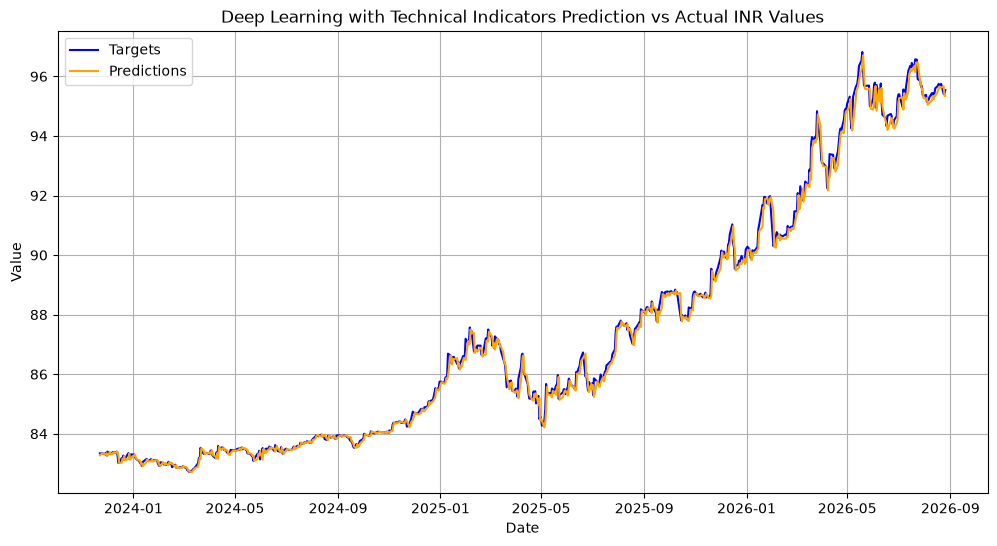

In [18]:
deep_ta_prediction_results = predict_and_store_log_return_model(
    model=model_dl_ta,
    model_name="Deep Learning with Technical Indicators",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_ta = deep_ta_prediction_results["train_predictions"]
predicted_prices_ta = deep_ta_prediction_results["test_predictions"]
actual_train_prices_ta = deep_ta_prediction_results["train_actual_prices"]
actual_prices_ta = deep_ta_prediction_results["test_actual_prices"]
deep_ta_train_metrics = deep_ta_prediction_results["train_metrics"]
deep_ta_metrics = deep_ta_prediction_results["test_metrics"]

print(
    f"Test MAE: {deep_ta_metrics['mae']:.4f}, "
    f"Test MSE: {deep_ta_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_ta,
    actual_prices_ta,
    x_values=test_df_ta.index,
    title="Deep Learning with Technical Indicators Prediction vs Actual INR Values",
)

## ADD NEW TEMPORAL FEATURES

In [19]:
TEMPORAL_FEATURES_NUMBER = 5  # Number of temporal features to include

In [30]:
import pandas as pd

def create_temporal_features(df, target_columns=None, num_features=5):
    """Add lagged temporal features"""
    df = df.copy()

    if target_columns is None:
        target_columns = [
            column for column in df.columns
            if column != "TARGET_NEXT"
        ]

    lagged_features = [
        df[target_columns]
        .shift(lag)
        .add_suffix(f"_lag_{lag}")
        for lag in range(1, num_features + 1)
    ]

    return pd.concat([df, *lagged_features], axis=1)


In [21]:
train_df_temp = create_temporal_features(train_df_ta.copy(), None, TEMPORAL_FEATURES_NUMBER)
val_df_temp = create_temporal_features(val_df_ta.copy(), None, TEMPORAL_FEATURES_NUMBER)
test_df_temp = create_temporal_features(test_df_ta.copy(), None, TEMPORAL_FEATURES_NUMBER)

In [22]:
train_df_temp.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5508 entries, 1999-02-01 to 2021-02-22
Columns: 103 entries, INR to Log_Returns_lag_5
dtypes: float64(103)
memory usage: 4.4 MB


In [23]:
feature_scaler_temp = fit_standard_scaler(train_df_temp, all_features)

train_targets = train_df_temp["TARGET_NEXT"]
val_targets = val_df_temp["TARGET_NEXT"]
test_targets = test_df_temp["TARGET_NEXT"]
target_scaler = fit_standard_scaler(train_targets)

X_train = normalize_to_tensor(train_df_temp, feature_scaler_temp, all_features)
X_val = normalize_to_tensor(val_df_temp, feature_scaler_temp, all_features)
X_test = normalize_to_tensor(test_df_temp, feature_scaler_temp, all_features)
y_train = normalize_to_tensor(train_targets, target_scaler)
y_val = normalize_to_tensor(val_targets, target_scaler)
y_test = normalize_to_tensor(test_targets, target_scaler)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

In [24]:
model_dl_temp = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 128),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(64, 1)
)
model_dl_temp_optimizer = optim.Adam(
    model_dl_temp.parameters(),
    lr=0.001,
)
model_dl_temp_loss_function = nn.MSELoss()

In [25]:
train_losses_dl_temp = train_torch_model(
    model_dl_temp,
    model_dl_temp_optimizer,
    model_dl_temp_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 0.9963, Val Loss: 0.4463
Epoch 20/100, Train Loss: 0.9871, Val Loss: 0.4451
Epoch 30/100, Train Loss: 0.9838, Val Loss: 0.4440
Epoch 40/100, Train Loss: 0.9841, Val Loss: 0.4452
Epoch 50/100, Train Loss: 0.9809, Val Loss: 0.4458
Epoch 60/100, Train Loss: 0.9781, Val Loss: 0.4466
Epoch 70/100, Train Loss: 0.9726, Val Loss: 0.4455
Epoch 80/100, Train Loss: 0.9792, Val Loss: 0.4453
Epoch 90/100, Train Loss: 0.9702, Val Loss: 0.4470
Epoch 100/100, Train Loss: 0.9641, Val Loss: 0.4462


Test MAE: 0.1466, Test MSE: 0.0527


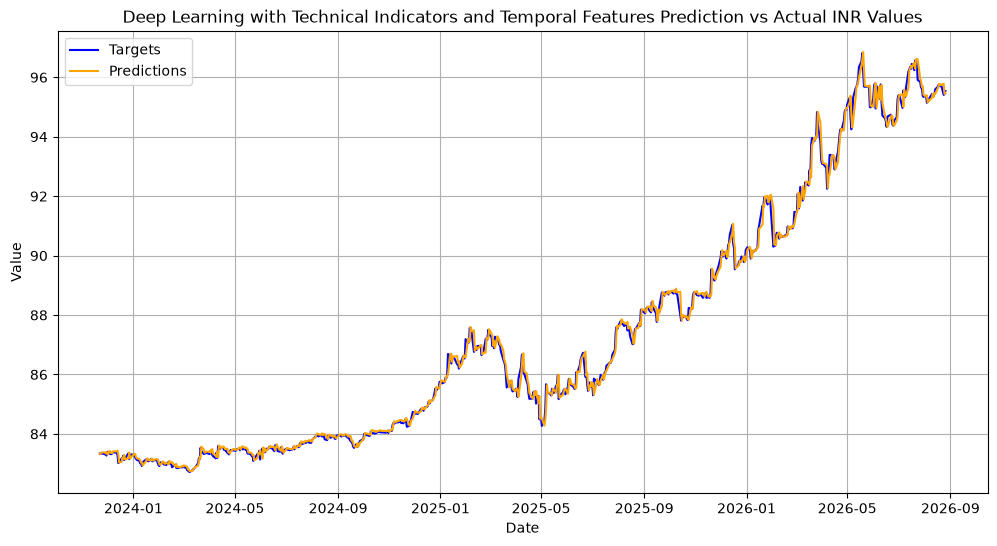

In [26]:
deep_temp_prediction_results = predict_and_store_log_return_model(
    model=model_dl_temp,
    model_name="Deep Learning with Technical Indicators and Temporal Features",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_temp = deep_temp_prediction_results["train_predictions"]
predicted_prices_temp = deep_temp_prediction_results["test_predictions"]
actual_train_prices_temp = deep_temp_prediction_results["train_actual_prices"]
actual_prices_temp = deep_temp_prediction_results["test_actual_prices"]
deep_temp_train_metrics = deep_temp_prediction_results["train_metrics"]
deep_temp_metrics = deep_temp_prediction_results["test_metrics"]

print(
    f"Test MAE: {deep_temp_metrics['mae']:.4f}, "
    f"Test MSE: {deep_temp_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_temp,
    actual_prices_temp,
    x_values=test_df_ta.index,
    title="Deep Learning with Technical Indicators and Temporal Features Prediction vs Actual INR Values",
)

### TEMPORAL FEATURES WITH LSTM